# Clasificación de animales con COI · V14 AMD

**Entrada.** Un fragmento de COI de 540 bases, codificado en one-hot.

**Respuestas.**

- **Grupo y especie.** La rama de grupo acepta un grupo del catálogo y la rama de especie asigna una de sus especies conocidas.
- **Grupo y especie desconocida.** La rama de grupo acepta un grupo y la rama de especie elige la categoría «especie desconocida» de ese grupo.
- **Grupo desconocido.** La rama de grupo rechaza el grupo y la especie queda sin evaluar.

**Cómo empezar.**

1. En VS Code, abrí **Trabajo Final** y elegí el kernel local con **PyTorch para ROCm**.
2. Usá **Ejecutar todo**. El **bloque 6** entrena grupo desde cero durante **200 épocas**. Al terminar recupera y congela los mejores pesos de grupo de esta corrida.
3. El **bloque 7** entrena especie desde cero durante **350 épocas**. Al validar cada época, usa las decisiones del grupo congelado para decidir qué secuencias evaluar y qué especies pueden competir.
4. Seguí las trazas por separado en los bloques 6 y 7. Guardá el notebook para conservar sus salidas. El checkpoint, los historiales y la validación se guardan en **Resultados → V14_AMD**.

**Consultar una corrida terminada.** En un kernel nuevo, ejecutá los bloques 1 a 5 y pasá a los bloques 8 y 9. Así se cargan los mejores pesos del checkpoint y las trazas de los bloques 6 y 7 quedan visibles.


## 1. Rutas, GPU y parámetros

- **Carpeta de trabajo.** Ejecutá el notebook desde Trabajo Final. `CARPETA_TRABAJO = Path(".")` toma esa carpeta como base para las rutas de datos y resultados.
- **GPU.** La primera celda prepara MIOpen en Windows, comprueba que PyTorch detecte la GPU AMD mediante ROCm y muestra el dispositivo elegido.
- **Entrenamiento de grupo.** Usamos Adam en `0.001`, lote de **512**, `weight_decay` de **0**, temperatura de **0,01** y regularización de los pesos de posición de **0,10**. La capa de rechazo tiene **16 neuronas**.
- **Entrenamiento de especie.** Usamos Adam en `0.0001`, lote de **2048**, `weight_decay` de **0,0001**, dos GRU de **192** unidades y dropout de **0,10**.
- **Pesos de la pérdida.** Grupo usa **35/25/40** y especie usa **75/25/0**, en el orden de especie conocida, especie nueva de grupo conocido y grupo nuevo. Los lotes de especie incluyen los casos con peso positivo.
- **Épocas.** Grupo hace **200** y especie **350**, con tasas de aprendizaje fijas y sin parada temprana. En cada rama guardamos la mejor época según su promedio de validación.
- **Lotes de validación.** Grupo evalúa todas las secuencias en lotes de hasta 2048. Especie evalúa las que reciben un grupo del catálogo.
- **Retomar la V14.** Conservá el nombre de la corrida y su configuración para continuar desde la última época guardada. Para comenzar otra corrida desde cero, elegí un `NOMBRE_RONDA` nuevo.


In [1]:
import ctypes
import hashlib
import importlib.util
import io
import json
import os
import tempfile
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# MIOpen en Windows necesita las cabeceras completas de HIP para las GRU.
def _ruta_para_hiprtc(ruta):
    texto = str(Path(ruta).resolve())
    if " " not in texto:
        return texto.replace("\\", "/")
    funcion = ctypes.WinDLL("kernel32", use_last_error=True).GetShortPathNameW
    funcion.argtypes = [ctypes.c_wchar_p, ctypes.c_wchar_p, ctypes.c_uint]
    funcion.restype = ctypes.c_uint
    buffer = ctypes.create_unicode_buffer(32768)
    if not funcion(texto, buffer, len(buffer)) or " " in buffer.value:
        raise RuntimeError("HIPRTC necesita rutas sin espacios para las cabeceras de HIP.")
    return buffer.value.replace("\\", "/")


def _preparar_miopen_windows():
    if os.name != "nt":
        return
    sdk = importlib.util.find_spec("_rocm_sdk_core")
    if sdk is None or not sdk.submodule_search_locations:
        raise RuntimeError("Elegí un kernel con el paquete ROCm SDK Core instalado.")
    include = Path(next(iter(sdk.submodule_search_locations))) / "include"
    if not (include / "hip" / "hip_runtime.h").is_file():
        raise RuntimeError("Faltan las cabeceras de HIP del SDK de ROCm.")
    temporal_usuario = Path(os.environ.get("LOCALAPPDATA", tempfile.gettempdir()))
    if "LOCALAPPDATA" in os.environ:
        temporal_usuario /= "Temp"
    temporal_usuario.mkdir(parents=True, exist_ok=True)
    carpeta = Path(tempfile.mkdtemp(prefix="miopen-coi-", dir=temporal_usuario))
    cabecera = carpeta / "compat_miopen.hpp"
    cabecera.write_text("#pragma once\n#undef MIOPEN_DONT_USE_HIP_RUNTIME_HEADERS\n", encoding="ascii")
    opciones = f"-include {_ruta_para_hiprtc(cabecera)} -I{_ruta_para_hiprtc(include)}"
    anteriores = os.environ.get("HIPRTC_COMPILE_OPTIONS_APPEND", "").strip()
    os.environ["HIPRTC_COMPILE_OPTIONS_APPEND"] = " ".join(x for x in (anteriores, opciones) if x)
    cache = temporal_usuario / "miopen_coi_hip_headers"
    for variable, nombre in (("MIOPEN_USER_DB_PATH", "db"), ("MIOPEN_CUSTOM_CACHE_DIR", "kernels")):
        destino = cache / nombre
        destino.mkdir(parents=True, exist_ok=True)
        os.environ[variable] = str(destino)


_preparar_miopen_windows()  # Configurar HIPRTC antes de importar PyTorch.

import torch
from IPython.display import HTML, Image, display
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

if not torch.version.hip:
    raise RuntimeError("Elegí en VS Code un kernel de Python con PyTorch para ROCm.")
if not torch.cuda.is_available():
    raise RuntimeError("PyTorch con ROCm no detectó una GPU AMD. Revisá el driver y el entorno de Python.")

nombres_gpu = [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]
# Si hay varias placas, preferimos la RX 7900 XT cuando aparece por su nombre.
indice_gpu = next((i for i, nombre in enumerate(nombres_gpu) if " 7900 XT " in f" {nombre.upper()} "), 0)
DISPOSITIVO = torch.device("cuda", indice_gpu)
torch.set_float32_matmul_precision("highest")
# Habilita MIOpen para convoluciones y GRU con las cabeceras corregidas.
torch.backends.cudnn.enabled = True

CARPETA_TRABAJO = Path(".")  # Ejecutá el notebook desde la carpeta Trabajo Final.

DATOS = CARPETA_TRABAJO / "Dataset Final"
DATOS_ESPECIE_DESCONOCIDA = CARPETA_TRABAJO / "Dataset Especie Desconocida"
DATOS_GRUPOS_DESCONOCIDOS = CARPETA_TRABAJO / "Dataset Grupos Desconocidos"
CARPETA_RESULTADOS = CARPETA_TRABAJO / "Resultados"
NOMBRE_RONDA = "V14_AMD"
RESULTADOS = CARPETA_RESULTADOS / NOMBRE_RONDA

if Path(NOMBRE_RONDA).name != NOMBRE_RONDA or NOMBRE_RONDA in ("", ".", ".."):
    raise ValueError("NOMBRE_RONDA debe ser el nombre de una carpeta dentro de Resultados.")


In [2]:
SEMILLA = 42
LONGITUD = 540
MIN_ESPECIES_POR_GRUPO = 5
MIN_EJEMPLARES_POR_ESPECIE = 20
LOTE_VALIDACION = 2048
TEMPERATURA_GRUPO = 0.01
DROPOUT = 0.10
UNIDADES_GRU = 192

HIPERPARAMETROS_GRUPO = {
    "lote": 512,
    "lr": 0.0010,
    "weight_decay": 0.0,
    "max_epocas": 200,
    "regularizacion_posiciones": 0.10,
}
HIPERPARAMETROS_ESPECIE = {
    "lote": 2048,
    "lr": 0.0001,
    "weight_decay": 0.0001,
    "max_epocas": 350,
}
CASOS = ["conocida", "especie_nueva", "grupo_nuevo"]
PESOS_CASOS_GRUPO = {"conocida": 0.35, "especie_nueva": 0.25, "grupo_nuevo": 0.40}
PESOS_CASOS_ESPECIE = {"conocida": 0.75, "especie_nueva": 0.25, "grupo_nuevo": 0.0}
GRUPO_DESCONOCIDO = "grupo desconocido"
ESPECIE_DESCONOCIDA = "especie desconocida"
ESPECIE_NO_EVALUADA = "especie no evaluada"

for pesos in (PESOS_CASOS_GRUPO, PESOS_CASOS_ESPECIE):
    if set(pesos) != set(CASOS) or not all(peso >= 0 for peso in pesos.values()) or not np.isclose(sum(pesos.values()), 1):
        raise ValueError("Los pesos de los tres casos deben ser no negativos y sumar 1.")
for parametros in (HIPERPARAMETROS_GRUPO, HIPERPARAMETROS_ESPECIE):
    if min(parametros["lote"], parametros["max_epocas"]) < 1:
        raise ValueError("El lote y el máximo de épocas deben ser positivos.")

print("Dispositivo:", torch.cuda.get_device_name(DISPOSITIVO))
print("ROCm/HIP:", torch.version.hip)
print("Carpeta de resultados:", RESULTADOS)
print("Entrenamiento de grupo:", HIPERPARAMETROS_GRUPO, "| reparto:", PESOS_CASOS_GRUPO)
print("Entrenamiento de especie:", HIPERPARAMETROS_ESPECIE, "| reparto:", PESOS_CASOS_ESPECIE)


Dispositivo: AMD Radeon RX 7900 XT
ROCm/HIP: 7.15.26333
Carpeta de resultados: Resultados\V14_AMD
Entrenamiento de grupo: {'lote': 512, 'lr': 0.001, 'weight_decay': 0.0, 'max_epocas': 200, 'regularizacion_posiciones': 0.1} | reparto: {'conocida': 0.35, 'especie_nueva': 0.25, 'grupo_nuevo': 0.4}
Entrenamiento de especie: {'lote': 2048, 'lr': 0.0001, 'weight_decay': 0.0001, 'max_epocas': 350} | reparto: {'conocida': 0.75, 'especie_nueva': 0.25, 'grupo_nuevo': 0.0}


## 2. Datos, etiquetas, perfiles y pesos

- **Leer las tres carpetas.** Cargamos `entrenamiento.csv` y `validacion.csv` de Dataset Final, Dataset Especie Desconocida y Dataset Grupos Desconocidos. La validación reserva especies completas y diez grupos externos. Los archivos de prueba final quedan reservados.
- **Verificar las etiquetas.** Comprobamos el catálogo, la separación entre particiones y la reserva de especies y grupos completos. Las accesiones pueden aportar secuencias de entrenamiento. El mínimo de 20 se comprueba con ejemplares identificados.
- **Construir un perfil por especie conocida.** Elegimos la base más frecuente en cada una de las 540 posiciones entre sus ejemplares de entrenamiento. Asociamos cada uno de los 10.875 perfiles con el grupo al que pertenece. Guardamos la firma de los perfiles para verificar la reanudación.
- **Preparar las etiquetas.** Para grupo usamos el grupo real o la opción «grupo desconocido». Para especie usamos la especie real, «especie desconocida» del grupo real o «grupo desconocido», según el caso. Estas son las categorías de salida de la V12.
- **Ponderar y formar los lotes.** Cada caso reparte su peso entre sus grupos en la rama de grupo y entre sus especies en la rama de especie. El peso de cada grupo o especie se distribuye entre sus ejemplares. Los lotes de especie incluyen los casos con peso positivo. La validación sigue midiendo los tres casos.


In [3]:
COLUMNAS = ["id", "grupo", "especie", "secuencia"]

def firma_archivo(ruta):
    with ruta.open("rb") as archivo:
        return hashlib.file_digest(archivo, "sha256").hexdigest()


def columna(tabla: pd.DataFrame, nombre: str) -> pd.Series:
    datos = tabla[nombre]
    if not isinstance(datos, pd.Series):
        raise ValueError(f"Se esperaba una sola columna para {nombre!r}.")
    return datos


def leer_tabla(ruta, con_evidencia=False):
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta {ruta}. Revisá las carpetas del bloque 1.")
    columnas = set(COLUMNAS)
    if con_evidencia:
        columnas.add("tipo_evidencia")
    tabla = pd.read_csv(
        ruta,
        usecols=lambda columna: columna in columnas,
        dtype=str,
        keep_default_na=False,
    )
    if con_evidencia and "tipo_evidencia" not in tabla:
        tabla["tipo_evidencia"] = "ejemplar"
    if tabla.empty or columna(tabla, "id").duplicated().any() or (tabla == "").any().any():
        raise ValueError(f"{ruta.name} tiene filas incompletas o identificadores repetidos.")
    return tabla, firma_archivo(ruta)


def codificar_bases(secuencias: pd.Series) -> torch.Tensor:
    equivalencias = np.zeros(256, dtype=np.uint8)
    for indice, letra in enumerate("ACGT"):
        equivalencias[ord(letra)] = indice

    bases = np.empty((len(secuencias), LONGITUD), dtype=np.uint8)
    for desde in range(0, len(secuencias), 8192):
        lote = secuencias.iloc[desde:desde + 8192]
        if not lote.str.fullmatch(rf"[ACGT]{{{LONGITUD}}}").all():
            raise ValueError(f"Cada secuencia debe tener {LONGITUD} bases y solo letras A, C, G y T.")
        letras = np.frombuffer("".join(lote).encode("ascii"), dtype=np.uint8)
        bases[desde:desde + len(lote)] = equivalencias[letras].reshape(-1, LONGITUD)
    return torch.from_numpy(bases)


def a_one_hot(bases):
    # Pasamos de [ejemplares, posiciones] a [ejemplares, 4 bases, posiciones].
    return F.one_hot(bases.long(), num_classes=4).float().transpose(1, 2)

conocidas_ent, firma_entrenamiento = leer_tabla(DATOS / "entrenamiento.csv")
val_conocidas, firma_val_conocidas = leer_tabla(DATOS / "validacion.csv")

nuevas_ent, firma_especie_desconocida = leer_tabla(
    DATOS_ESPECIE_DESCONOCIDA / "entrenamiento.csv",
    con_evidencia=True,
)
val_nuevas, firma_val_nuevas = leer_tabla(
    DATOS_ESPECIE_DESCONOCIDA / "validacion.csv",
)

abst_grupo_ent, firma_grupos_ent = leer_tabla(DATOS_GRUPOS_DESCONOCIDOS / "entrenamiento.csv")
abst_grupo_val, firma_grupos_val = leer_tabla(DATOS_GRUPOS_DESCONOCIDOS / "validacion.csv")

contenido_catalogo = (DATOS / "catalogos" / "especies.csv").read_bytes()
catalogo_original = pd.read_csv(
    io.BytesIO(contenido_catalogo),
    usecols=["grupo", "especie", "rol", "ejemplares_disponibles"],
    dtype=str,
)
ficha_grupos = pd.read_csv(DATOS / "catalogos" / "grupos.csv", usecols=["grupo"], dtype=str)
firma_datos = (
    firma_entrenamiento, firma_val_conocidas, firma_val_nuevas, firma_especie_desconocida,
    firma_grupos_ent, firma_grupos_val, hashlib.sha256(contenido_catalogo).hexdigest(),
)


In [4]:
grupos = sorted(conocidas_ent["grupo"].unique())
grupos_abstencion = set(abst_grupo_ent["grupo"])
grupos_val_nuevos = set(abst_grupo_val["grupo"])
if ficha_grupos["grupo"].duplicated().any() or set(ficha_grupos["grupo"]) != set(grupos):
    raise ValueError("Los grupos del entrenamiento deben coincidir con el catálogo grupos.csv.")
if (not grupos_abstencion or len(grupos_val_nuevos) != 10
        or grupos_abstencion & grupos_val_nuevos
        or set(grupos) & (grupos_abstencion | grupos_val_nuevos)):
    raise ValueError("Se requieren grupos externos de entrenamiento y diez grupos externos reservados para validación.")

nombres_asignados = catalogo_original["especie"].str.strip().str.casefold()
for tabla in (nuevas_ent, abst_grupo_ent, abst_grupo_val):
    nombres = tabla["especie"].str.strip().str.casefold()
    if nombres.isin(nombres_asignados).any():
        raise ValueError("Un ejemplar de abstención pertenece a una especie asignada en Dataset Final.")
if not columna(nuevas_ent, "grupo").isin(grupos).all():
    raise ValueError("Dataset Especie Desconocida debe aportar especies nuevas de grupos del catálogo.")
desconocidas_verificadas = nuevas_ent.loc[nuevas_ent["tipo_evidencia"].ne("accesion")]
conteos_desconocidas = desconocidas_verificadas.groupby(["grupo", "especie"]).size()
if conteos_desconocidas.ge(MIN_EJEMPLARES_POR_ESPECIE).any():
    raise ValueError("Hay especies de abstención que ya cumplen el mínimo de ejemplares.")

externas = pd.concat([abst_grupo_ent, abst_grupo_val])
ids_externas = columna(externas, "id")
secuencias_externas = columna(externas, "secuencia")
if (ids_externas.duplicated().any() or secuencias_externas.duplicated().any()
        or ids_externas.isin(columna(nuevas_ent, "id")).any()
        or secuencias_externas.isin(columna(nuevas_ent, "secuencia")).any()
        or ids_externas.isin(columna(conocidas_ent, "id")).any()
        or secuencias_externas.isin(columna(conocidas_ent, "secuencia")).any()):
    raise ValueError("Hay identificadores o secuencias repetidos en los ejemplos de grupo desconocido.")

entrenamiento = pd.concat([
    conocidas_ent.assign(caso="conocida"),
    nuevas_ent.assign(caso="especie_nueva"),
    abst_grupo_ent.assign(caso="grupo_nuevo"),
], ignore_index=True)
validacion = pd.concat([
    val_conocidas.assign(caso="conocida"),
    val_nuevas.assign(caso="especie_nueva"),
    abst_grupo_val.assign(caso="grupo_nuevo"),
], ignore_index=True)

catalogo_entrenamiento = conocidas_ent[["especie", "grupo"]].drop_duplicates().set_index("especie")
catalogo = columna(catalogo_entrenamiento, "grupo").sort_index()
fichas_conocidas = catalogo_original.loc[catalogo_original["rol"].eq("conocida")].set_index("especie")
if (not catalogo.index.is_unique or set(catalogo) != set(grupos)
        or not catalogo.value_counts().ge(MIN_ESPECIES_POR_GRUPO).all()):
    raise ValueError("Cada grupo del catálogo tiene que aportar al menos cinco especies conocidas.")
if (not fichas_conocidas.index.is_unique
        or not fichas_conocidas["grupo"].sort_index().equals(catalogo)
        or not fichas_conocidas["ejemplares_disponibles"].astype(int).ge(MIN_EJEMPLARES_POR_ESPECIE).all()):
    raise ValueError("El catálogo de entrenamiento debe coincidir con las especies aptas de especies.csv.")
grupos_conocidas_val = columna(val_conocidas, "especie").map(catalogo)
if not grupos_conocidas_val.eq(columna(val_conocidas, "grupo")).all():
    raise ValueError("La validación de conocidas no coincide con el catálogo.")
if not columna(val_nuevas, "grupo").isin(grupos).all():
    raise ValueError("La validación de especies nuevas debe corresponder a grupos del catálogo.")
ids_entrenamiento = columna(entrenamiento, "id")
ids_validacion = columna(validacion, "id")
if (set(columna(validacion, "caso")) != set(CASOS) or set(columna(entrenamiento, "caso")) != set(CASOS)
        or ids_entrenamiento.duplicated().any() or ids_validacion.duplicated().any()
        or ids_validacion.isin(ids_entrenamiento).any()
        or columna(validacion, "secuencia").isin(columna(entrenamiento, "secuencia")).any()):
    raise ValueError("Revisá que ambos conjuntos cubran los tres casos sin repetir ejemplares entre ellos.")
nombres_ent = entrenamiento["especie"].str.strip().str.casefold()
nombres_val_nuevas = validacion.loc[validacion["caso"].ne("conocida"), "especie"].str.strip().str.casefold()
if nombres_val_nuevas.isin(nombres_ent).any():
    raise ValueError("Una especie reservada para validación aparece en entrenamiento.")

especies = catalogo.index.to_list()
indice_grupo = {nombre: i for i, nombre in enumerate(grupos)}
indice_especie = {nombre: i for i, nombre in enumerate(especies)}

grupo_fuera = len(grupos)
especie_fuera = len(especies)
categoria_grupo_desconocido = len(especies) + len(grupos)
indice_especie_desconocida = {
    grupo: len(especies) + indice_grupo[grupo] for grupo in grupos
}
nombres_grupo = [*grupos, GRUPO_DESCONOCIDO]
nombres_especie = [*especies, ESPECIE_DESCONOCIDA]
nombres_categorias = [
    *especies,
    *[f"{ESPECIE_DESCONOCIDA} de {grupo}" for grupo in grupos],
    GRUPO_DESCONOCIDO,
]
grupo_por_categoria = torch.tensor(
    [indice_grupo[grupo] for grupo in catalogo] + list(range(len(grupos))) + [grupo_fuera],
    dtype=torch.long,
)
if len(nombres_categorias) != 11024:
    raise ValueError("El catálogo de esta corrida debe formar las 11.024 categorías de la V12.")

reparto_grupos = {
    "catalogo": grupos,
    "abstencion_entrenamiento": sorted(grupos_abstencion),
    "grupos_nuevos_validacion": sorted(grupos_val_nuevos),
}
print(f"Catálogo: {len(grupos)} grupos y {len(especies)} especies.")
print(f"Grupos externos: {len(grupos_abstencion)} para entrenar y {len(grupos_val_nuevos)} para validar.")
print(f"Catálogo de salida de la V12: {len(nombres_categorias):,} categorías.")
composicion = pd.DataFrame({
    "Entrenamiento": entrenamiento["caso"].value_counts().reindex(CASOS),
    "Validación": validacion["caso"].value_counts().reindex(CASOS),
})
display(composicion)


Catálogo: 148 grupos y 10875 especies.
Grupos externos: 2675 para entrenar y 10 para validar.
Catálogo de salida de la V12: 11,024 categorías.


,Entrenamiento,Validación
caso,,
conocida,1030599,53381
especie_nueva,316404,14964
grupo_nuevo,154624,1001


In [5]:
def objetivos_grupo(tabla):
    categorias = tabla["grupo"].map(indice_grupo).fillna(grupo_fuera)
    return torch.from_numpy(categorias.to_numpy(dtype=np.int64, copy=True))


def objetivos_especie(tabla):
    categorias = pd.Series(categoria_grupo_desconocido, index=tabla.index, dtype="int64")
    conocidas = tabla["caso"].eq("conocida")
    nuevas = tabla["caso"].eq("especie_nueva")
    categorias.loc[conocidas] = tabla.loc[conocidas, "especie"].map(indice_especie)
    categorias.loc[nuevas] = tabla.loc[nuevas, "grupo"].map(indice_especie_desconocida)
    return torch.from_numpy(categorias.to_numpy(dtype=np.int64, copy=True))


def ponderar_casos(tabla, pesos_casos, unidad):
    # El peso del caso se reparte entre las clases y entre sus ejemplares.
    n_clases = tabla.groupby("caso")[unidad].transform("nunique")
    n_ejemplares = tabla.groupby(["caso", unidad])["id"].transform("size")
    pesos = len(tabla) * tabla["caso"].map(pesos_casos) / (n_clases * n_ejemplares)
    return torch.from_numpy(pesos.to_numpy(dtype=np.float32, copy=True))



# Las secuencias conocidas ocupan las primeras filas, en el orden de conocidas_ent.
bases_ent = codificar_bases(columna(entrenamiento, "secuencia"))
bases_conocidas = bases_ent[:len(conocidas_ent)].numpy()
grupo_por_perfil = grupo_por_categoria[:len(especies)]
perfiles = np.empty((len(especies), LONGITUD), dtype=np.uint8)
for especie, filas in conocidas_ent.groupby("especie").indices.items():
    ejemplares = bases_conocidas[filas]
    frecuencias = np.stack([(ejemplares == base).sum(axis=0) for base in range(4)])
    perfiles[indice_especie[especie]] = frecuencias.argmax(axis=0)
perfiles_bases = torch.from_numpy(perfiles)
firma_perfiles = hashlib.sha256(perfiles.tobytes()).hexdigest()
del bases_conocidas

perfil_propio = columna(entrenamiento, "especie").map(indice_especie).fillna(-1)
datos_grupo = TensorDataset(
    bases_ent, objetivos_grupo(entrenamiento),
    torch.from_numpy(perfil_propio.to_numpy(dtype=np.int64, copy=True)),
    ponderar_casos(entrenamiento, PESOS_CASOS_GRUPO, "grupo"),
)
lotes_grupo_ent = DataLoader(datos_grupo, batch_size=HIPERPARAMETROS_GRUPO["lote"], shuffle=True)

incluir_en_especie = columna(entrenamiento, "caso").map(PESOS_CASOS_ESPECIE).gt(0)
entrenamiento_especie = entrenamiento.loc[incluir_en_especie]
datos_especie = TensorDataset(
    bases_ent[torch.from_numpy(incluir_en_especie.to_numpy(dtype=np.bool_, copy=True))],
    objetivos_especie(entrenamiento_especie),
    ponderar_casos(entrenamiento_especie, PESOS_CASOS_ESPECIE, "especie"),
)
lotes_especie_ent = DataLoader(datos_especie, batch_size=HIPERPARAMETROS_ESPECIE["lote"], shuffle=True)

del bases_ent
bases_validacion = codificar_bases(columna(validacion, "secuencia"))
grupos_validacion = objetivos_grupo(validacion)
categorias_validacion = objetivos_especie(validacion)
lotes_validacion = DataLoader(TensorDataset(bases_validacion, grupos_validacion), batch_size=LOTE_VALIDACION)
print(f"Perfiles de referencia: {len(perfiles_bases):,}, uno por especie conocida.")
print(f"Secuencias disponibles para entrenamiento: {len(entrenamiento):,}. Secuencias de validación: {len(validacion):,}.")
print(f"Secuencias en los lotes de entrenamiento de especie: {len(datos_especie):,}.")


Perfiles de referencia: 10,875, uno por especie conocida.
Secuencias disponibles para entrenamiento: 1,501,627. Secuencias de validación: 69,346.
Secuencias en los lotes de entrenamiento de especie: 1,347,003.


## 3. Arquitectura de la red

**Rama de grupo · Perfiles y capa de rechazo.**
- **Entrada.** La secuencia original en one-hot (4 × 540) y los 10.875 perfiles del bloque 2. Cada perfil representa una especie conocida.
- **Coincidencias.** Comparamos las bases de la secuencia con las de cada perfil y sumamos los pesos de las posiciones que coinciden. Al iniciar la V14, esos pesos son uniformes y se ajustan durante el entrenamiento. Para cada grupo conservamos la mejor coincidencia entre sus perfiles. Obtenemos 148 puntajes, uno por grupo, en la escala de la V11.
- **Grupo desconocido.** La capa de rechazo recibe el mejor puntaje menos 85 y la diferencia entre los dos puntajes más altos. Una capa densa de 16 neuronas con ReLU combina esas dos señales. La capa de salida devuelve un ajuste que se suma al mejor puntaje para crear el puntaje de «grupo desconocido». Gana el mayor de los 149 puntajes.

**Rama de especie · CNN–GRU de la V12.**
- **Entrada.** Durante el entrenamiento, la CNN–GRU recibe la secuencia original de 4 × 540 junto con su etiqueta real. Al validar o clasificar, la secuencia pasa a la CNN–GRU si la primera rama elige un grupo del catálogo. Si gana «grupo desconocido», se devuelve «especie sin evaluar».
- **Convoluciones y pooling.** Cada bloque contiene dos convoluciones con BatchNorm y ReLU y termina con MaxPool de tamaño 2. Los tamaños de kernel son 7 y 5, 5 y 5, y 5 y 3. Las salidas de los tres bloques son 64 × 270, 128 × 135 y 192 × 67.
- **GRU y capa densa.** Las dos GRU procesan 67 pasos de 192 valores. Concatenamos el máximo y el promedio de los estados de la segunda GRU para obtener 384 valores. Una capa densa los reduce a 128. Durante el entrenamiento se aplica dropout de 0,10 en la capa de 128 valores.
- **Salida y filtro.** La rama de especie produce 11.024 puntajes. Al predecir, el grupo elegido por la primera rama determina qué categorías compiten. Se consideran sus especies conocidas y su propia categoría «especie desconocida». Gana el mayor puntaje entre esas categorías y se conserva el grupo elegido por la primera rama.


In [6]:
def bloque_convolucional(canales_entrada, canales_salida, ventana_1, ventana_2):
    return nn.Sequential(
        nn.Conv1d(canales_entrada, canales_salida, ventana_1, padding=ventana_1 // 2, bias=False),
        nn.BatchNorm1d(canales_salida),
        nn.ReLU(),
        nn.Conv1d(canales_salida, canales_salida, ventana_2, padding=ventana_2 // 2, bias=False),
        nn.BatchNorm1d(canales_salida),
        nn.ReLU(),
        nn.MaxPool1d(2),
    )


class RedCOIV12(nn.Module):
    def __init__(self, numero_categorias, dropout, unidades_gru):
        super().__init__()
        self.convoluciones = nn.Sequential(
            bloque_convolucional(4, 64, 7, 5),      # 4 × 540 → 64 × 270
            bloque_convolucional(64, 128, 5, 5),    # 64 × 270 → 128 × 135
            bloque_convolucional(128, 192, 5, 3),   # 128 × 135 → 192 × 67
        )
        self.gru_1 = nn.GRU(input_size=192, hidden_size=unidades_gru, batch_first=True)
        self.gru_2 = nn.GRU(input_size=unidades_gru, hidden_size=unidades_gru, batch_first=True)
        self.densa = nn.Sequential(
            nn.Linear(2 * unidades_gru, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.salida = nn.Linear(128, numero_categorias)

    def forward(self, secuencia):
        patrones = self.convoluciones(secuencia)
        pasos = patrones.transpose(1, 2).contiguous()  # [lote, 67 pasos, 192 valores]

        estados_primera, _ = self.gru_1(pasos)
        estados_segunda, _ = self.gru_2(estados_primera)
        # Las dos GRU entregan un estado por paso. Resumimos los 67 estados de la segunda.
        maximos = estados_segunda.amax(dim=1)
        promedios = estados_segunda.mean(dim=1)
        resumen = torch.cat((maximos, promedios), dim=1)  # [lote, 384]
        return self.salida(self.densa(resumen))


In [7]:
class RamaGrupo(nn.Module):
    perfiles: torch.Tensor
    grupo_por_perfil: torch.Tensor

    def __init__(self, perfiles, grupo_por_perfil, numero_grupos, temperatura, neuronas_rechazo):
        super().__init__()
        self.numero_grupos = numero_grupos
        self.temperatura = temperatura
        self.register_buffer("perfiles", a_one_hot(perfiles).flatten(1), persistent=False)
        self.register_buffer("grupo_por_perfil", grupo_por_perfil, persistent=False)
        self.peso_posiciones = nn.Parameter(torch.zeros(LONGITUD))
        self.salida_grupo_desconocido = nn.Sequential(
            nn.Linear(2, neuronas_rechazo),
            nn.ReLU(),
            nn.Linear(neuronas_rechazo, 1),
        )

    def pesos_por_posicion(self):
        # Todos los pesos empiezan en 1 y su promedio se mantiene en 1.
        return self.peso_posiciones.softmax(dim=0) * LONGITUD

    def forward(self, secuencia, perfil_propio=None):
        secuencia_ponderada = secuencia * self.pesos_por_posicion()
        coincidencias = F.linear(secuencia_ponderada.flatten(1), self.perfiles)
        if perfil_propio is not None:
            mascara = torch.zeros_like(coincidencias, dtype=torch.bool)
            mascara.scatter_(1, perfil_propio.clamp_min(0)[:, None], perfil_propio.ge(0)[:, None])
            coincidencias = coincidencias.masked_fill(mascara, -torch.inf)

        # Cada columna de coincidencias tiene un grupo asignado.
        indices_grupo = self.grupo_por_perfil.expand(len(secuencia), -1)
        puntajes = coincidencias.new_full((len(secuencia), self.numero_grupos), -torch.inf)
        puntajes = puntajes.scatter_reduce(1, indices_grupo, coincidencias, reduce="amax")
        puntajes = puntajes / (LONGITUD * self.temperatura)

        dos_mejores = puntajes.topk(2, dim=1).values
        mejor = dos_mejores[:, 0]
        margen = mejor - dos_mejores[:, 1]
        rasgos = torch.stack((mejor - 0.85 / self.temperatura, margen), dim=1)
        puntaje_desconocido = mejor[:, None] + self.salida_grupo_desconocido(rasgos)
        return torch.cat((puntajes, puntaje_desconocido), dim=1)

config_grupo = {
    "numero_grupos": len(grupos),
    "temperatura": TEMPERATURA_GRUPO,
    "neuronas_rechazo": 16,
}
config_especie = {
    "numero_categorias": len(nombres_categorias),
    "dropout": DROPOUT,
    "unidades_gru": UNIDADES_GRU,
}
torch.manual_seed(SEMILLA)
rama_grupo = RamaGrupo(perfiles_bases, grupo_por_perfil, **config_grupo).to(DISPOSITIVO)
rama_especie = RedCOIV12(**config_especie).to(DISPOSITIVO)
categorias_en_dispositivo = grupo_por_categoria.to(DISPOSITIVO)


def filtrar_especies(logits_especie, grupos_elegidos):
    # Para cada secuencia compiten solo las categorías del grupo elegido por la primera rama.
    candidatas = categorias_en_dispositivo[None, :].eq(grupos_elegidos[:, None])
    return logits_especie.masked_fill(~candidatas, -torch.inf)


def predecir_grupos(bases):
    return rama_grupo(a_one_hot(bases.to(DISPOSITIVO)))


def predecir_especies(bases):
    return rama_especie(a_one_hot(bases.to(DISPOSITIVO)))


def elegir_especies(puntajes_filtrados):
    categoria = puntajes_filtrados.argmax(dim=1)
    return torch.where(categoria < len(especies), categoria, especie_fuera)


## 4. Inicialización, guardado y reanudación

- **Iniciar desde cero.** El bloque 3 crea las dos ramas con la semilla de esta corrida. Grupo comienza con pesos uniformes por posición y una capa de rechazo recién inicializada. La CNN–GRU empieza con su propia inicialización.
- **Guardar cada época.** El checkpoint de la V14 guarda los mejores pesos, los pesos de la última época, el estado de Adam y el historial de cada rama. `origen_pesos.json` registra la inicialización y la configuración de la corrida.
- **Retomar una interrupción.** Con la misma carpeta y configuración, recuperamos el checkpoint de la V14 y Adam continúa desde la última época guardada. Al llegar a una rama terminada se recupera su mejor época.
- **Comprobar la corrida.** Verificamos los datos, los perfiles, las dos arquitecturas y los parámetros antes de retomar el entrenamiento.


In [8]:
def copiar_pesos(rama):
    return {nombre: tensor.detach().cpu().clone() for nombre, tensor in rama.state_dict().items()}


def guardar_checkpoint():
    temporal = ruta_checkpoint.with_suffix(".tmp")
    torch.save(estado, temporal)
    temporal.replace(ruta_checkpoint)


def guardar_historial(nombre, fase):
    ruta = RESULTADOS / f"historial_{nombre}.csv"
    temporal = ruta.with_suffix(".tmp")
    historial = pd.DataFrame(fase["historial"])
    historial.to_csv(temporal, index=False)
    temporal.replace(ruta)
    return historial


def guardar_origen_pesos():
    ruta = RESULTADOS / "origen_pesos.json"
    temporal = ruta.with_suffix(".tmp")
    temporal.write_text(json.dumps(origen_pesos, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporal.replace(ruta)



firma_corrida = {
    "version": "V14",
    "nombre_ronda": NOMBRE_RONDA,
    "firma_datos": firma_datos,
    "firma_perfiles": firma_perfiles,
    "reparto_grupos": reparto_grupos,
    "semilla": SEMILLA,
    "lote_validacion": LOTE_VALIDACION,
    "configuracion": {
        "grupo": {
            "hiperparametros": HIPERPARAMETROS_GRUPO,
            "pesos_casos": PESOS_CASOS_GRUPO,
            "modelo": config_grupo,
        },
        "especie": {
            "hiperparametros": HIPERPARAMETROS_ESPECIE,
            "pesos_casos": PESOS_CASOS_ESPECIE,
            "modelo": config_especie,
        },
    },
}
origen_pesos = {"modo": "desde cero", "checkpoint_origen": None, **firma_corrida}
ruta_checkpoint = RESULTADOS / "checkpoint.pt"
RESULTADOS.mkdir(parents=True, exist_ok=True)
if ruta_checkpoint.is_file():
    estado = torch.load(ruta_checkpoint, map_location="cpu", weights_only=True)
    if estado.get("firma") != firma_corrida:
        raise ValueError(f"{RESULTADOS.name} pertenece a otra configuración. Elegí otro NOMBRE_RONDA.")
    print(f"Checkpoint de la V14 disponible en {RESULTADOS}.")
elif any(archivo.name != "checkpoint.tmp" for archivo in RESULTADOS.iterdir()):
    raise ValueError(f"{RESULTADOS.name} ya tiene resultados. Elegí otro NOMBRE_RONDA.")
else:
    estado = {"firma": firma_corrida, "fases": {}}
    guardar_checkpoint()
    print("Corrida nueva. Ambas ramas arrancan desde cero.")
guardar_origen_pesos()


Checkpoint de la V14 disponible en Resultados\V14_AMD.


In [9]:
def entrenar_rama(nombre, rama, parametros, medir_epoca, metrica, claves_traza):
    fase = estado["fases"].get(nombre)
    if fase is not None and fase["terminada"]:
        rama.load_state_dict(fase["mejor_modelo"])
        rama.requires_grad_(False).eval()
        print(f"Rama de {nombre} ya terminada. Mejor época: {fase['mejor_epoca']} ({fase['motivo_fin']}).")
        return guardar_historial(nombre, fase), fase["mejor_epoca"]

    rama.requires_grad_(True)
    adam = torch.optim.Adam(rama.parameters(), lr=parametros["lr"], weight_decay=parametros["weight_decay"])
    if fase is None:
        medidas = medir_epoca(None)
        pesos = copiar_pesos(rama)
        fila = {"epoca": 0, "segundos": 0.0, **medidas, "mejor_epoca": 0, "sin_mejora": 0}
        fase = {
            "historial": [fila],
            "mejor_epoca": 0,
            "mejor_criterio": (fila[metrica], -fila["val_perdida"]),
            "sin_mejora": 0,
            "terminada": False,
            "mejor_modelo": pesos,
            "ultimo_modelo": pesos,
            "adam": adam.state_dict(),
        }
        estado["fases"][nombre] = fase
        guardar_checkpoint()
        guardar_historial(nombre, fase)
        print(f"{nombre.capitalize()} · Época 0 | promedio de validación {fila[metrica]:.2%}", flush=True)
    else:
        rama.load_state_dict(fase["ultimo_modelo"])
        adam.load_state_dict(fase["adam"])
        guardar_historial(nombre, fase)
        print(f"Retomando {nombre} después de la época {fase['historial'][-1]['epoca']}.", flush=True)

    primera = fase["historial"][-1]["epoca"] + 1
    for epoca in range(primera, parametros["max_epocas"] + 1):
        torch.manual_seed(SEMILLA + epoca)
        inicio = perf_counter()
        medidas = medir_epoca(adam)
        fila = {"epoca": epoca, "segundos": perf_counter() - inicio, **medidas}
        criterio = (fila[metrica], -fila["val_perdida"])
        pesos = copiar_pesos(rama)
        if criterio > fase["mejor_criterio"]:
            fase["mejor_epoca"] = epoca
            fase["mejor_criterio"] = criterio
            fase["mejor_modelo"] = pesos
            fase["sin_mejora"] = 0
        else:
            fase["sin_mejora"] += 1
        fila.update(mejor_epoca=fase["mejor_epoca"], sin_mejora=fase["sin_mejora"])
        fase["historial"].append(fila)
        fase["ultimo_modelo"] = pesos
        fase["adam"] = adam.state_dict()
        guardar_checkpoint()
        guardar_historial(nombre, fase)
        aciertos = " | ".join(f"{etiqueta} {fila[clave]:.2%}" for etiqueta, clave in claves_traza)
        print(
            f"{nombre.capitalize()} · Época {epoca:3d} | {fila['segundos']:.1f} s "
            f"| pérdida ent. {fila['ent_perdida']:.4f} | pérdida val. {fila['val_perdida']:.4f} "
            f"| {aciertos} | promedio {fila[metrica]:.2%} | mejor época {fila['mejor_epoca']} "
            f"| épocas sin mejora {fila['sin_mejora']}",
            flush=True,
        )

    fase["motivo_fin"] = f"{parametros['max_epocas']} épocas completas"
    fase["terminada"] = True
    rama.load_state_dict(fase["mejor_modelo"])
    rama.requires_grad_(False).eval()
    guardar_checkpoint()
    historial = guardar_historial(nombre, fase)
    print(f"Fin de {nombre}: {fase['motivo_fin']}. Mejor época: {fase['mejor_epoca']}.", flush=True)
    return historial, fase["mejor_epoca"]


## 5. Funciones de validación

- **Validar grupo.** Comprobamos el grupo correcto en especies conocidas y nuevas y el rechazo en grupos externos. Los tres aciertos se calculan con la salida de la rama de grupo.
- **Validar las respuestas completas.** La rama de grupo evalúa todas las secuencias. Reunimos las que reciben un grupo del catálogo y la rama de especie elige entre las categorías permitidas en ese grupo.
- **Promediar por clase.** En especies conocidas y especies nuevas se promedia por especie. En grupos externos se promedia por grupo. El promedio de las tres respuestas completas da el resultado general.
- **Medir las categorías de especie.** Para seguir el entrenamiento calculamos la pérdida de categoría sobre los ejemplares aceptados por grupo, antes de filtrar las categorías. Las métricas de acierto usan la decisión completa de las dos ramas.


In [10]:
def tasa_macro(tabla, aciertos, caso, unidad):
    filas = tabla["caso"].eq(caso)
    return float(aciertos.loc[filas].groupby(tabla.loc[filas, unidad]).mean().mean())


@torch.inference_mode()
def medir_grupos_validacion():
    rama_grupo.eval()
    grupos_elegidos = []
    perdidas = torch.zeros((), device=DISPOSITIVO)
    for bases, grupo_real in lotes_validacion:
        puntajes = predecir_grupos(bases)
        perdidas += F.cross_entropy(puntajes, grupo_real.to(DISPOSITIVO), reduction="sum")
        grupos_elegidos.append(puntajes.argmax(dim=1).cpu())

    ids_grupo = torch.cat(grupos_elegidos)
    aciertos = pd.Series(ids_grupo.eq(grupos_validacion).tolist(), index=validacion.index)
    tasas = {
        "val_grupo_en_conocidas": tasa_macro(validacion, aciertos, "conocida", "especie"),
        "val_grupo_en_especies_nuevas": tasa_macro(validacion, aciertos, "especie_nueva", "especie"),
        "val_abstencion_en_grupos_nuevos": tasa_macro(validacion, aciertos, "grupo_nuevo", "grupo"),
    }
    return ids_grupo, perdidas.item() / len(validacion), tasas


@torch.inference_mode()
def predecir_validacion(
    ids_grupo: torch.Tensor, lotes_aceptados: DataLoader, cantidad_aceptadas: int,
) -> tuple[pd.DataFrame, float]:
    rama_especie.eval()
    ids_especie = torch.full_like(ids_grupo, -1)
    perdidas = torch.zeros((), device=DISPOSITIVO)
    for (filas,) in lotes_aceptados:
        logits = predecir_especies(bases_validacion[filas])
        objetivo = categorias_validacion[filas].to(DISPOSITIVO)
        perdidas += F.cross_entropy(logits, objetivo, reduction="sum")
        puntajes = filtrar_especies(logits, ids_grupo[filas].to(DISPOSITIVO))
        ids_especie[filas] = elegir_especies(puntajes).cpu()

    perdida = perdidas.item() / cantidad_aceptadas if cantidad_aceptadas else float("inf")
    salida = pd.DataFrame(validacion.loc[:, ["id", "grupo", "especie", "caso"]], copy=True)
    salida["grupo_predicho"] = [nombres_grupo[indice] for indice in ids_grupo.tolist()]
    salida["especie_predicha"] = [nombres_especie[indice] if indice >= 0 else ESPECIE_NO_EVALUADA for indice in ids_especie.tolist()]
    sin_grupo = columna(salida, "grupo_predicho").eq(GRUPO_DESCONOCIDO).to_numpy(dtype=bool)
    sin_especie = columna(salida, "especie_predicha").eq(ESPECIE_DESCONOCIDA).to_numpy(dtype=bool)
    salida["respuesta"] = np.select(
        [sin_grupo, sin_especie], ["grupo_nuevo", "especie_nueva"], default="conocida",
    )
    return salida, perdida


def medir_respuestas(tabla):
    grupo_correcto = tabla["grupo_predicho"].eq(tabla["grupo"])
    especie_correcta = tabla["especie_predicha"].eq(tabla["especie"])
    sin_especie = tabla["especie_predicha"].eq(ESPECIE_DESCONOCIDA)
    sin_grupo = tabla["grupo_predicho"].eq(GRUPO_DESCONOCIDO)
    # La precisión al nombrar considera los ejemplos de grupos del catálogo.
    nombra = tabla["respuesta"].eq("conocida") & tabla["caso"].ne("grupo_nuevo")
    return {
        "grupo_correcto_en_conocidas": tasa_macro(tabla, grupo_correcto, "conocida", "especie"),
        "especie_correcta_en_conocidas": tasa_macro(tabla, grupo_correcto & especie_correcta, "conocida", "especie"),
        "grupo_correcto_en_especies_nuevas": tasa_macro(tabla, grupo_correcto, "especie_nueva", "especie"),
        "grupo_correcto_y_especie_desconocida": tasa_macro(tabla, grupo_correcto & sin_especie, "especie_nueva", "especie"),
        "grupo_desconocido_en_grupos_nuevos": tasa_macro(tabla, sin_grupo, "grupo_nuevo", "grupo"),
        "precision_al_nombrar": float((grupo_correcto & especie_correcta)[nombra].mean()) if nombra.any() else None,
    }




def cargar_mejores_pesos():
    fase_grupo = estado["fases"].get("grupo")
    fase_especie = estado["fases"].get("especie")
    if fase_grupo is None or fase_especie is None:
        raise RuntimeError("El checkpoint debe contener los pesos guardados de ambas ramas.")

    rama_grupo.load_state_dict(fase_grupo["mejor_modelo"])
    rama_grupo.requires_grad_(False).eval()
    rama_especie.load_state_dict(fase_especie["mejor_modelo"])
    rama_especie.requires_grad_(False).eval()
    return fase_grupo, fase_especie


casos_reales = {"conocida": "Conocida", "especie_nueva": "Especie nueva", "grupo_nuevo": "Grupo nuevo"}

CLAVES_RESPUESTA = (
    ("conocidas", "especie_correcta_en_conocidas"),
    ("especie nueva", "grupo_correcto_y_especie_desconocida"),
    ("grupo nuevo", "grupo_desconocido_en_grupos_nuevos"),
)
CLAVES_GRUPO = (
    ("grupo en conocidas", "val_grupo_en_conocidas"),
    ("grupo en especies nuevas", "val_grupo_en_especies_nuevas"),
    ("grupo nuevo", "val_abstencion_en_grupos_nuevos"),
)


def promedio_tres_casos(metricas):
    return sum(metricas[clave] for _, clave in CLAVES_RESPUESTA) / 3


## 6. Entrenamiento de grupo

- **Entrenar grupo.** Ajustamos los pesos de las posiciones y la capa de rechazo con Adam en `0.001` durante **200 épocas**. Usamos entropía cruzada ponderada y regularización de los pesos de posición.
- **Elegir la mejor época.** Validamos el acierto en los tres casos y guardamos el mayor promedio. Si dos épocas empatan, elegimos la de menor pérdida de validación.
- **Leer las trazas.** La época 0 mide los pesos iniciales. Desde la época 1 se muestran el tiempo, las pérdidas, los aciertos, el promedio y la mejor época. El historial completo se guarda en `historial_grupo.csv`.
- **Congelar grupo.** Al terminar cargamos la mejor época de grupo de esta corrida. Usamos sus decisiones para reunir las secuencias de validación que reciben un grupo del catálogo y fijar qué categorías pueden competir en especie.


In [11]:
def ajustar_grupo(optimizador):
    rama_grupo.train()
    acumulada = torch.zeros((), device=DISPOSITIVO)
    for bases, objetivo, perfil, pesos in lotes_grupo_ent:
        entrada = a_one_hot(bases.to(DISPOSITIVO))
        logits = rama_grupo(entrada, perfil.to(DISPOSITIVO))
        errores = F.cross_entropy(logits, objetivo.to(DISPOSITIVO), reduction="none")
        perdida = (errores * pesos.to(DISPOSITIVO)).mean()
        regularizacion = (rama_grupo.pesos_por_posicion() - 1).square().mean()
        optimizador.zero_grad()
        (perdida + HIPERPARAMETROS_GRUPO["regularizacion_posiciones"] * regularizacion).backward()
        optimizador.step()
        acumulada += perdida.detach() * len(bases)
    return acumulada.item() / len(datos_grupo)


def medir_epoca_grupo(optimizador):
    perdida_ent = ajustar_grupo(optimizador) if optimizador is not None else None
    _, perdida_val, tasas = medir_grupos_validacion()
    return {
        "ent_perdida": perdida_ent,
        "val_perdida": perdida_val,
        **tasas,
        "val_promedio_grupo": sum(tasas.values()) / len(tasas),
    }


In [12]:
historial_grupo, epoca_grupo = entrenar_rama(
    "grupo", rama_grupo, HIPERPARAMETROS_GRUPO, medir_epoca_grupo,
    "val_promedio_grupo", CLAVES_GRUPO,
)

ids_grupo_validacion, _, tasas_grupo = medir_grupos_validacion()
aciertos = " | ".join(f"{etiqueta} {tasas_grupo[clave]:.2%}" for etiqueta, clave in CLAVES_GRUPO)
promedio_grupo = sum(tasas_grupo.values()) / len(tasas_grupo)
print(f"Grupo congelado · {NOMBRE_RONDA} · época {epoca_grupo} | {aciertos} | promedio {promedio_grupo:.2%}", flush=True)

filas_aceptadas = ids_grupo_validacion.ne(grupo_fuera).nonzero(as_tuple=True)[0]
lotes_aceptados = DataLoader(TensorDataset(filas_aceptadas), batch_size=LOTE_VALIDACION)
print(f"Validación de grupo: {len(ids_grupo_validacion):,} secuencias, {len(filas_aceptadas):,} aceptadas.", flush=True)


Grupo · Época 0 | promedio de validación 23.35%
Grupo · Época   1 | 141.5 s | pérdida ent. 0.5607 | pérdida val. 0.1196 | grupo en conocidas 99.54% | grupo en especies nuevas 84.96% | grupo nuevo 68.36% | promedio 84.29% | mejor época 1 | épocas sin mejora 0
Grupo · Época   2 | 129.0 s | pérdida ent. 0.4429 | pérdida val. 0.1086 | grupo en conocidas 99.60% | grupo en especies nuevas 87.21% | grupo nuevo 72.22% | promedio 86.35% | mejor época 2 | épocas sin mejora 0
Grupo · Época   3 | 118.8 s | pérdida ent. 0.4185 | pérdida val. 0.1079 | grupo en conocidas 99.61% | grupo en especies nuevas 88.20% | grupo nuevo 71.07% | promedio 86.30% | mejor época 2 | épocas sin mejora 1
Grupo · Época   4 | 119.6 s | pérdida ent. 0.4087 | pérdida val. 0.1066 | grupo en conocidas 99.62% | grupo en especies nuevas 88.80% | grupo nuevo 71.62% | promedio 86.68% | mejor época 4 | épocas sin mejora 0
Grupo · Época   5 | 119.0 s | pérdida ent. 0.4038 | pérdida val. 0.1077 | grupo en conocidas 99.61% | grupo 

## 7. Entrenamiento de especie

- **Entrenar especie.** La CNN–GRU parte de su inicialización y aprende con las etiquetas del conjunto de entrenamiento. Usamos Adam en `0.0001` durante **350 épocas** con entropía cruzada ponderada. El **75 %** del peso corresponde a especies conocidas y el **25 %** a especies nuevas de grupos conocidos.
- **Usar los grupos del bloque 6.** Ejecutá el bloque 6 antes de esta etapa. En cada validación se reutilizan sus decisiones. Para cada secuencia aceptada, la rama de especie elige entre las especies de su grupo y la categoría «especie desconocida» de ese grupo.
- **Elegir la mejor época.** Se elige por el promedio de las tres respuestas completas. En caso de empate, elegimos la de menor pérdida de validación.
- **Leer las trazas.** La época 0 mide la especie recién inicializada con el grupo elegido en el bloque 6. «Grupo nuevo» refleja el acierto fijo de la rama de grupo congelada. Desde la época 1 se muestran el tiempo, las pérdidas, los tres aciertos completos, la mejor época y cuántas épocas lleva sin mejorar. El historial completo se guarda en `historial_especie.csv`.
- **Evaluar al terminar.** El bloque 8 carga los mejores pesos de las dos ramas y calcula las predicciones de validación.


In [12]:
def ajustar_especie(optimizador):
    rama_especie.train()
    acumulada = torch.zeros((), device=DISPOSITIVO)
    for bases, objetivo, pesos in lotes_especie_ent:
        logits = predecir_especies(bases)
        errores = F.cross_entropy(logits, objetivo.to(DISPOSITIVO), reduction="none")
        perdida = (errores * pesos.to(DISPOSITIVO)).mean()
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        acumulada += perdida.detach() * len(bases)
    return acumulada.item() / len(datos_especie)


def medir_epoca_especie(optimizador):
    perdida_ent = ajustar_especie(optimizador) if optimizador is not None else None
    tabla, perdida_val = predecir_validacion(ids_grupo_validacion, lotes_aceptados, len(filas_aceptadas))
    metricas = medir_respuestas(tabla)
    return {
        "ent_perdida": perdida_ent,
        "val_perdida": perdida_val,
        **metricas,
        "val_promedio": promedio_tres_casos(metricas),
    }


In [13]:
if not estado["fases"].get("grupo", {}).get("terminada") or "lotes_aceptados" not in globals():
    raise RuntimeError("Ejecutá el bloque 6 para preparar los grupos de la validación de especie.")

historial_especie, epoca_especie = entrenar_rama(
    "especie", rama_especie, HIPERPARAMETROS_ESPECIE, medir_epoca_especie,
    "val_promedio", CLAVES_RESPUESTA,
)


Especie · Época 0 | promedio de validación 28.07%
Especie · Época   1 | 250.9 s | pérdida ent. 7.8979 | pérdida val. 7.2068 | conocidas 1.20% | especie nueva 79.28% | grupo nuevo 77.18% | promedio 52.55% | mejor época 1 | épocas sin mejora 0
Especie · Época   2 | 248.8 s | pérdida ent. 6.0823 | pérdida val. 6.0185 | conocidas 4.05% | especie nueva 73.56% | grupo nuevo 77.18% | promedio 51.59% | mejor época 1 | épocas sin mejora 1
Especie · Época   3 | 248.6 s | pérdida ent. 5.1652 | pérdida val. 5.1207 | conocidas 9.60% | especie nueva 71.25% | grupo nuevo 77.18% | promedio 52.67% | mejor época 3 | épocas sin mejora 0
Especie · Época   4 | 248.8 s | pérdida ent. 4.5000 | pérdida val. 4.5051 | conocidas 15.61% | especie nueva 66.91% | grupo nuevo 77.18% | promedio 53.23% | mejor época 4 | épocas sin mejora 0
Especie · Época   5 | 250.0 s | pérdida ent. 4.0136 | pérdida val. 4.4364 | conocidas 17.02% | especie nueva 59.91% | grupo nuevo 77.18% | promedio 51.37% | mejor época 4 | épocas s

## 8. Resultados de validación

- **Cargar la corrida guardada.** Si abriste un kernel nuevo, ejecutá los bloques 1 a 5 y luego las dos celdas de este bloque. La primera carga las mejores épocas de grupo y especie y calcula las predicciones.
- **Leer el cuadro de aciertos.** Para especies conocidas y nuevas mostramos el acierto de grupo por separado de la respuesta completa. Ambas filas usan las mismas muestras de su caso. En grupos nuevos evaluamos si la rama de grupo respondió «grupo desconocido».
- **Interpretar el promedio.** El promedio usa las tres respuestas completas, resaltadas en negrita. Debajo mostramos la fiabilidad al asignar un nombre de especie.
- **Ver las curvas completas.** Cada rama tiene una gráfica de pérdida y una de aciertos de validación. Grupo muestra de la época **0 a la 200** y especie de la época **0 a la 350**. La línea punteada marca la mejor época de cada rama.
- **Leer la matriz de decisiones.** Las filas muestran el caso real y las columnas muestran la respuesta de la V14. Las celdas cuentan ejemplares. La figura tiene un eje horizontal ancho para que se lean las etiquetas.
- **Consultar los archivos.** Guardamos los porcentajes, las predicciones por ejemplar, las curvas, las matrices y el origen de los pesos en la carpeta de la corrida.


In [11]:
if "cargar_mejores_pesos" not in globals():
    raise RuntimeError("Ejecutá los bloques 1 a 5 antes de validar el checkpoint.")

fase_grupo, fase_especie = cargar_mejores_pesos()
epoca_grupo, epoca_especie = fase_grupo["mejor_epoca"], fase_especie["mejor_epoca"]
historial_grupo = pd.DataFrame(fase_grupo["historial"])
historial_especie = pd.DataFrame(fase_especie["historial"])

ids_grupo_validacion, _, _ = medir_grupos_validacion()
filas_aceptadas = ids_grupo_validacion.ne(grupo_fuera).nonzero(as_tuple=True)[0]
lotes_aceptados = DataLoader(TensorDataset(filas_aceptadas), batch_size=LOTE_VALIDACION)
predicciones, _ = predecir_validacion(ids_grupo_validacion, lotes_aceptados, len(filas_aceptadas))

metricas = medir_respuestas(predicciones)
resultados = {
    "corrida": NOMBRE_RONDA,
    "epoca_grupo": epoca_grupo,
    "epoca_especie": epoca_especie,
    **metricas,
    "val_promedio": promedio_tres_casos(metricas),
}
pd.DataFrame([resultados]).to_csv(RESULTADOS / "metricas_validacion.csv", index=False)

predicciones.to_csv(RESULTADOS / "predicciones_validacion.csv", index=False)

precision_nombres = metricas["precision_al_nombrar"]
texto_precision = f"{precision_nombres:.2%}" if precision_nombres is not None else "Sin respuestas con nombre"

display(HTML(f"""
<p><strong>Mejores pesos de {NOMBRE_RONDA}.</strong> Grupo en la época {epoca_grupo} y especie en la época {epoca_especie}.</p>
<style>
.coi-validacion {{ border-collapse: collapse; font-size: 14px; margin: 12px 0; }}
.coi-validacion th, .coi-validacion td {{ padding: 10px 14px; text-align: left; border-bottom: 1px solid #8886; }}
.coi-validacion .valor {{ text-align: right; white-space: nowrap; }}
.coi-validacion .caso {{ vertical-align: middle; border-left: 1px solid #8886; }}
</style>
<table class="coi-validacion">
  <thead><tr><th>Qué debe acertar la red</th><th>Validación</th><th>Caso de la secuencia</th></tr></thead>
  <tbody>
    <tr>
      <td>Identificar el grupo correcto</td><td class="valor">{metricas['grupo_correcto_en_conocidas']:.2%}</td>
      <td rowspan="2" class="caso"><strong>Grupo y especie<br>entrenados</strong></td>
    </tr>
    <tr>
      <td><strong>Identificar el grupo y la especie correctos</strong></td><td class="valor"><strong>{metricas['especie_correcta_en_conocidas']:.2%}</strong></td>
    </tr>
    <tr>
      <td>Identificar el grupo correcto</td><td class="valor">{metricas['grupo_correcto_en_especies_nuevas']:.2%}</td>
      <td rowspan="2" class="caso"><strong>Grupo entrenado<br>y especie nueva</strong></td>
    </tr>
    <tr>
      <td><strong>Identificar el grupo correcto y responder «especie desconocida»</strong></td><td class="valor"><strong>{metricas['grupo_correcto_y_especie_desconocida']:.2%}</strong></td>
    </tr>
    <tr>
      <td><strong>Responder «grupo desconocido»</strong></td><td class="valor"><strong>{metricas['grupo_desconocido_en_grupos_nuevos']:.2%}</strong></td>
      <td class="caso"><strong>Grupo nuevo</strong></td>
    </tr>
  </tbody>
</table>
<p><strong>Promedio de las tres respuestas completas — {resultados['val_promedio']:.2%}</strong></p>
<p>En los dos primeros casos se promedia por especie y en grupo nuevo se promedia por grupo.</p>
<table class="coi-validacion">
  <thead><tr><th>Fiabilidad al asignar un nombre de especie</th><th>Validación</th></tr></thead>
  <tbody><tr>
    <td>Grupo y especie correctos entre las respuestas con nombre,<br>sobre muestras de grupos entrenados</td>
    <td class="valor">{texto_precision}</td>
  </tr></tbody>
</table>
"""))

respuestas = {"conocida": "Dio nombre", "especie_nueva": "Especie desconocida", "grupo_nuevo": "Grupo desconocido"}
matriz = pd.crosstab(predicciones["caso"], predicciones["respuesta"]).reindex(index=CASOS, columns=CASOS, fill_value=0)
matriz = matriz.rename(index=casos_reales, columns=respuestas)
matriz.to_csv(RESULTADOS / "matriz_decisiones.csv", index_label="caso_real")
display(matriz)

es_grupo_conocido = columna(predicciones, "caso").ne("grupo_nuevo")
grupo_real = columna(predicciones, "grupo").where(es_grupo_conocido, GRUPO_DESCONOCIDO)
matriz_grupos = pd.crosstab(grupo_real, predicciones["grupo_predicho"])
matriz_grupos = matriz_grupos.reindex(index=nombres_grupo, columns=nombres_grupo, fill_value=0)
matriz_grupos.to_csv(RESULTADOS / "matriz_grupos.csv", index_label="grupo_real")

composicion.to_csv(RESULTADOS / "composicion_datos.csv", index_label="caso")
print("Resultados guardados en:", RESULTADOS)


respuesta,Dio nombre,Especie desconocida,Grupo desconocido
caso,,,
Conocida,49459,3772,150
Especie nueva,3121,10251,1592
Grupo nuevo,118,103,780


Resultados guardados en: Resultados\V14_AMD


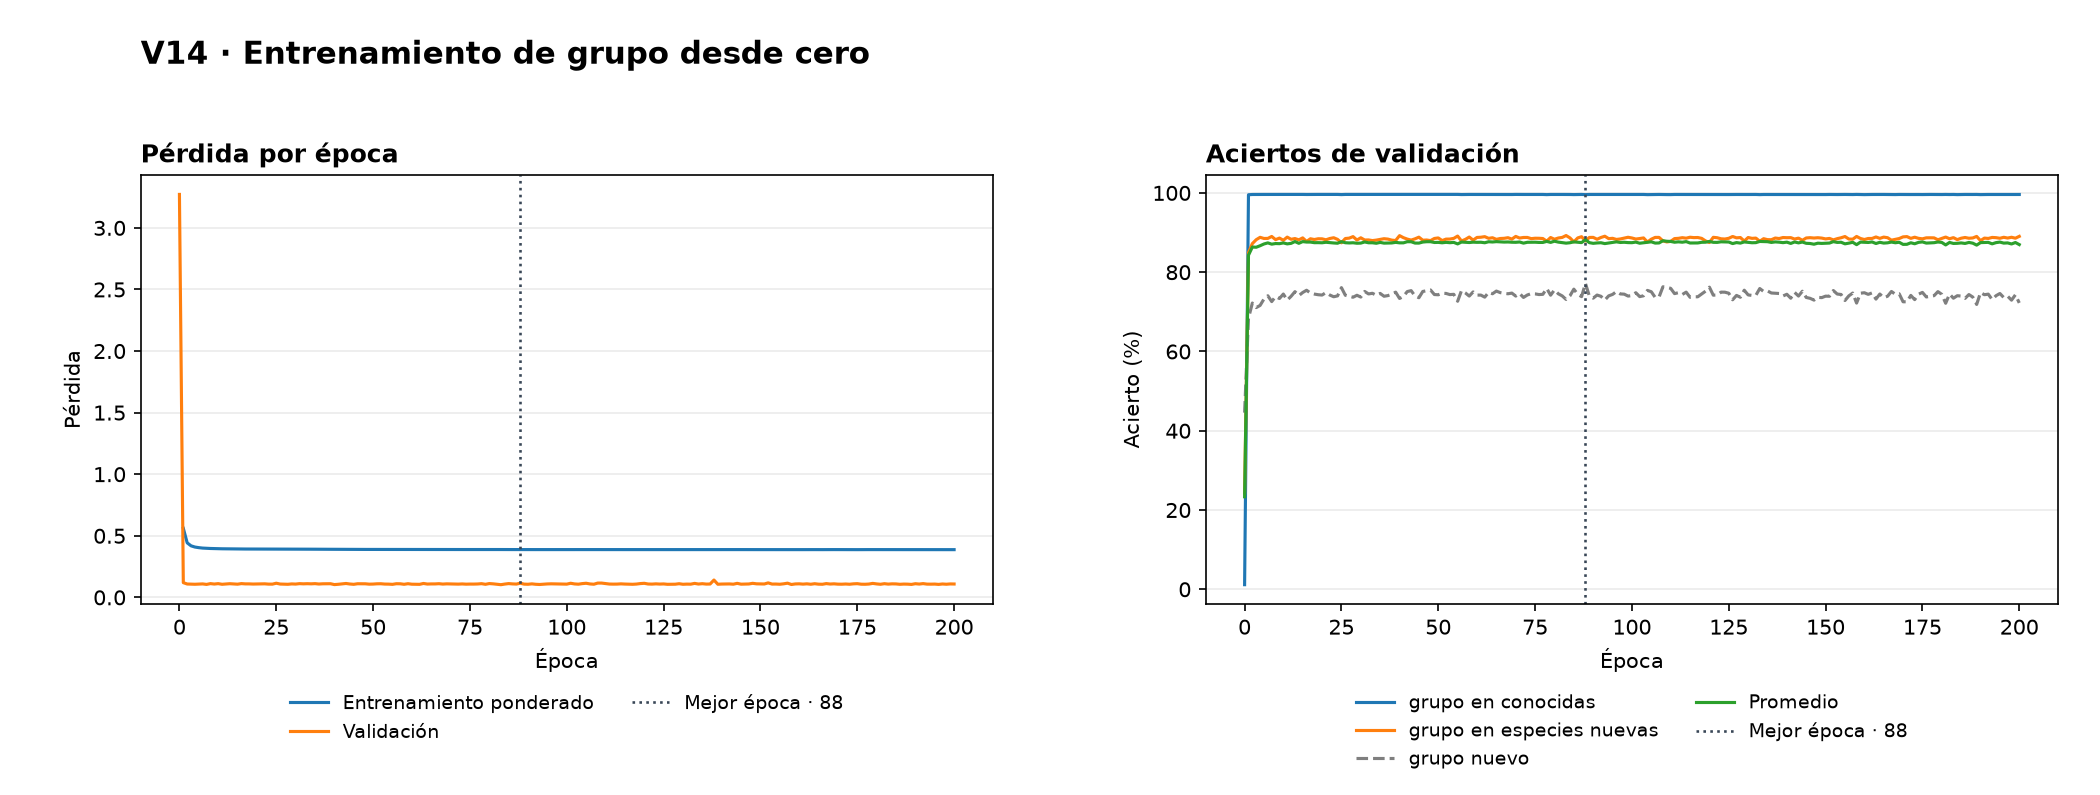

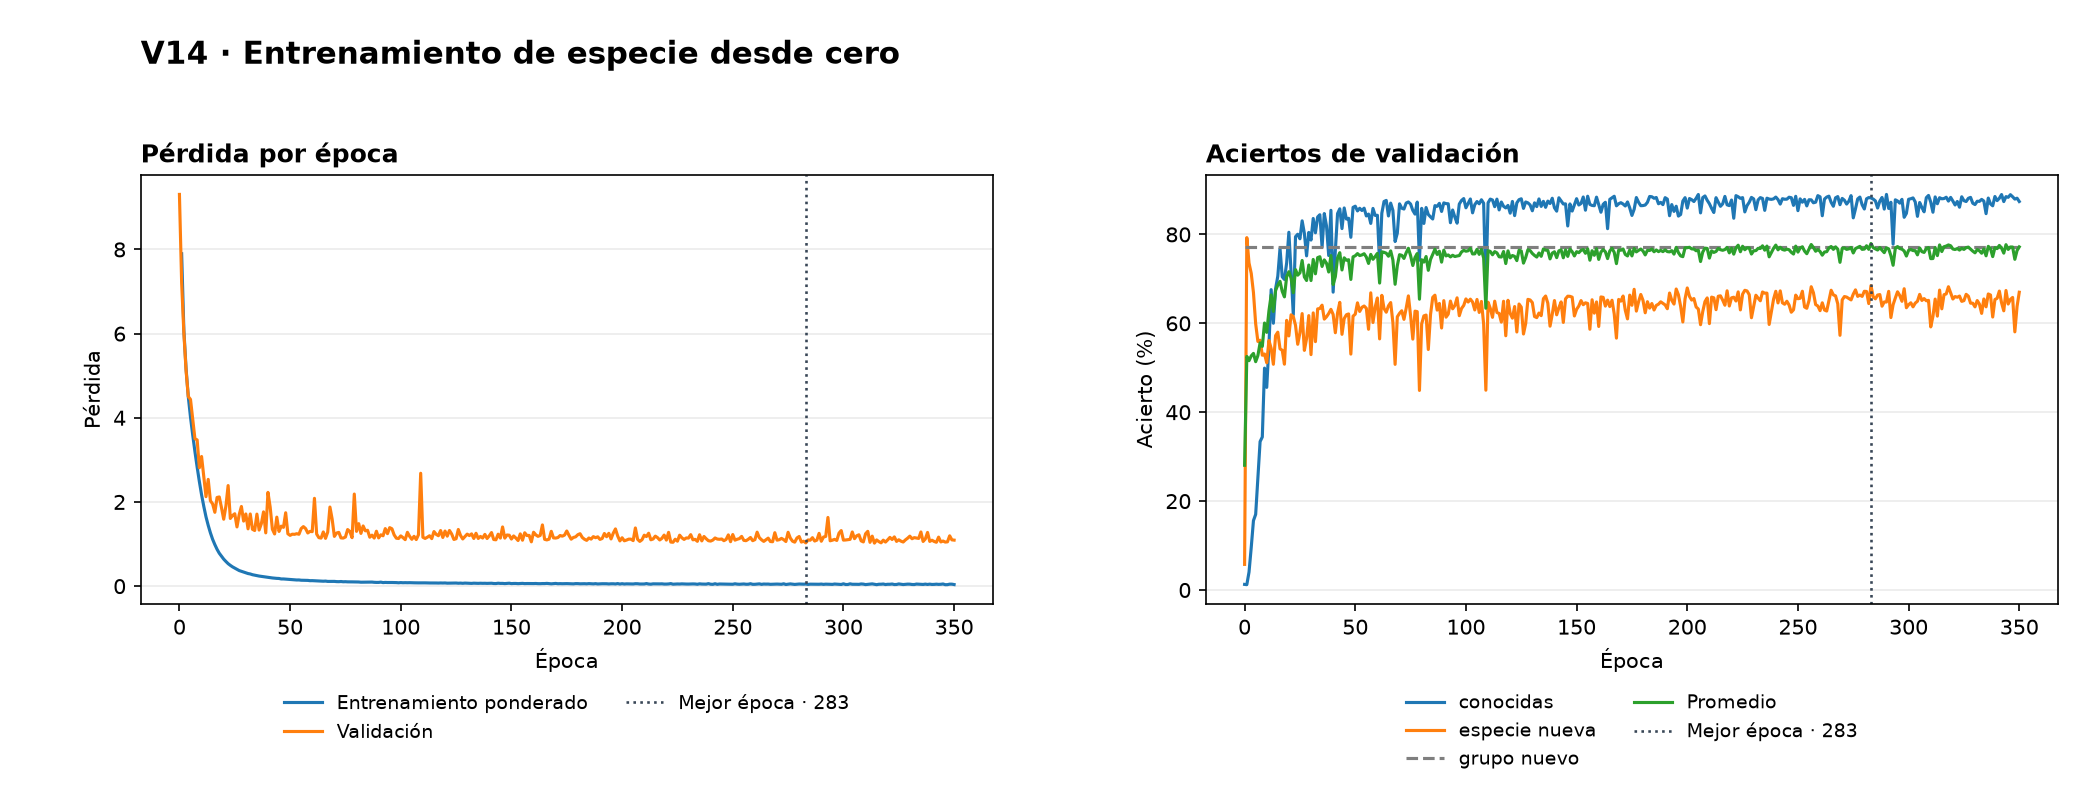

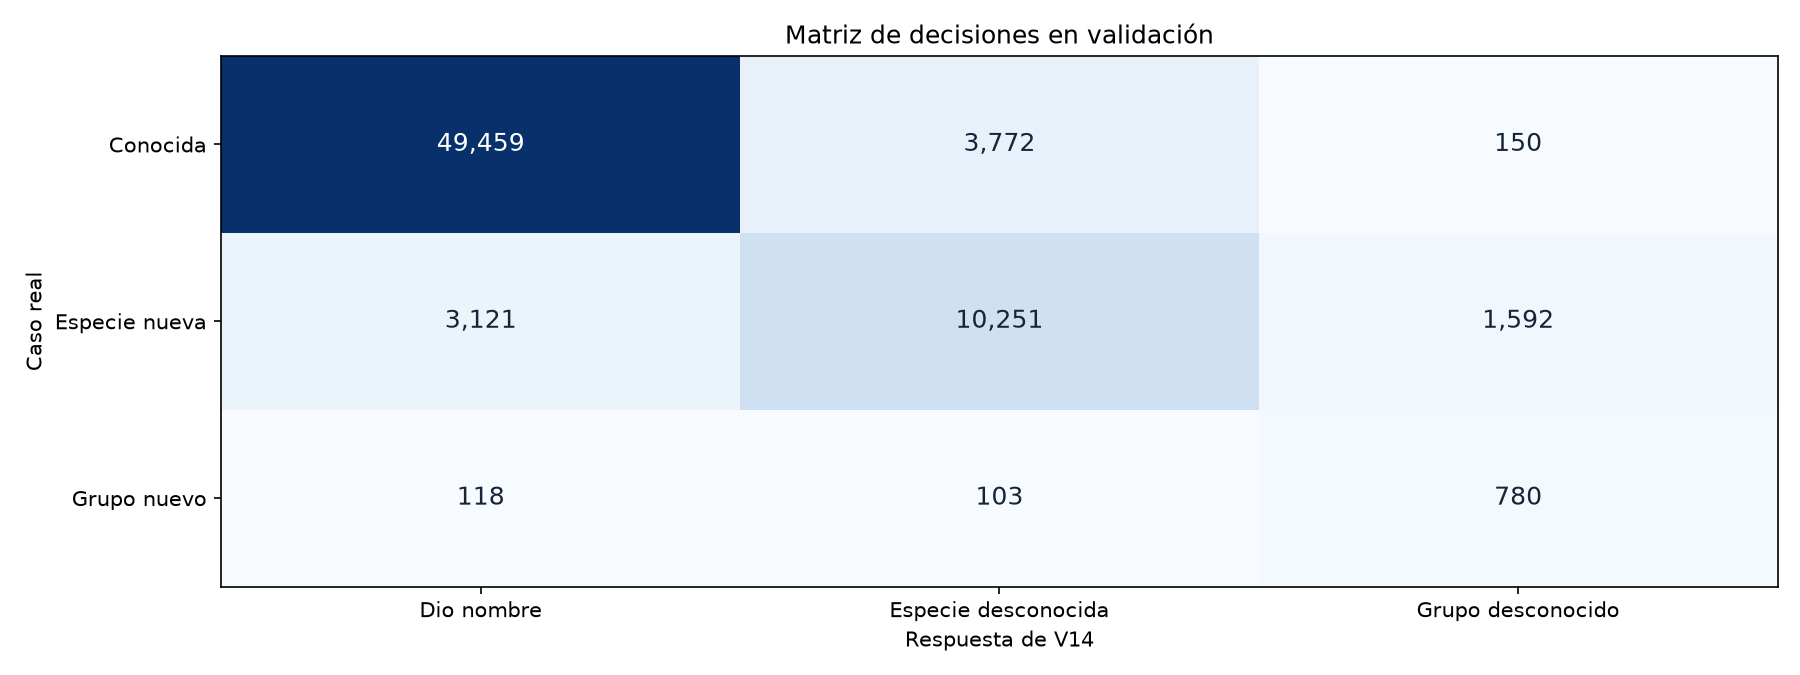

In [12]:
if "matriz" not in globals():
    raise RuntimeError("Ejecutá primero la celda anterior del bloque 8.")

def graficar_historial(historial, mejor_epoca, claves_acierto, clave_promedio, titulo, archivo):
    fig, ejes = plt.subplots(1, 2, figsize=(14, 5.3))
    fig.subplots_adjust(left=0.067, right=0.98, bottom=0.24, top=0.78, wspace=0.25)
    epocas = historial["epoca"]

    ejes[0].plot(epocas, historial["ent_perdida"], label="Entrenamiento ponderado")
    ejes[0].plot(epocas, historial["val_perdida"], label="Validación")
    colores_acierto = ("tab:blue", "tab:orange", "tab:gray", "tab:green")
    for (etiqueta, clave), color in zip((*claves_acierto, ("Promedio", clave_promedio)), colores_acierto):
        ejes[1].plot(epocas, 100 * historial[clave], color=color, label=etiqueta,
                     linestyle="--" if color == "tab:gray" else "-")

    ejes[0].set_ylabel("Pérdida")
    ejes[1].set_ylabel("Acierto (%)")
    for eje, subtitulo in zip(ejes, ("Pérdida por época", "Aciertos de validación")):
        eje.set_title(subtitulo, loc="left", fontweight="bold")
        eje.axvline(mejor_epoca, color="#384656", linewidth=1.25, linestyle=":",
                    label=f"Mejor época · {mejor_epoca}")
        eje.set_xlabel("Época")
        eje.grid(axis="y", alpha=0.25)
        eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9, frameon=False)
    fig.suptitle(titulo, x=0.067, y=0.95, ha="left", fontsize=15, fontweight="bold")
    ruta = RESULTADOS / archivo
    fig.savefig(ruta, dpi=150)
    plt.close(fig)
    display(Image(filename=str(ruta)))


graficar_historial(historial_grupo, epoca_grupo, CLAVES_GRUPO, "val_promedio_grupo",
                   "V14 · Entrenamiento de grupo desde cero", "curvas_grupo.png")
graficar_historial(historial_especie, epoca_especie, CLAVES_RESPUESTA, "val_promedio",
                   "V14 · Entrenamiento de especie desde cero", "curvas_especie.png")


fig, ax = plt.subplots(figsize=(12, 4.5))
valores = matriz.to_numpy()
ax.imshow(valores, cmap="Blues", aspect="auto")
for i in range(len(CASOS)):
    for j in range(len(CASOS)):
        color = "white" if valores[i, j] > valores.max() / 2 else "#152436"
        ax.text(j, i, f"{valores[i, j]:,}", ha="center", va="center", fontsize=12, color=color)
ax.set_xticks(range(len(CASOS)), labels=matriz.columns)
ax.set_yticks(range(len(CASOS)), labels=matriz.index)
ax.set(xlabel="Respuesta de V14", ylabel="Caso real", title="Matriz de decisiones en validación")
fig.tight_layout()
ruta_matriz = RESULTADOS / "matriz_decisiones.png"
fig.savefig(ruta_matriz, dpi=150)
plt.close(fig)
display(Image(filename=str(ruta_matriz)))


## 9. Clasificar una secuencia

- **Entrada.** `clasificar_secuencia(secuencia)` recibe un fragmento de COI de 540 bases y aplica la misma decisión que la validación.
- **Salida.** Devuelve el grupo elegido y los puntajes de la rama de grupo expresados como probabilidades. Si se acepta un grupo, también devuelve la especie y los puntajes normalizados de las categorías permitidas para ese grupo. Si se rechaza el grupo, devuelve «especie sin evaluar».
- **Ejemplos.** Mostramos un ejemplar de validación de cada caso junto con su etiqueta real y la respuesta de la V14.

**Cargar los pesos.** En un kernel nuevo, ejecutá primero los bloques 1 a 5. Esta celda recupera las mejores épocas del checkpoint antes de clasificar los ejemplos.


In [13]:
if "cargar_mejores_pesos" not in globals():
    raise RuntimeError("Ejecutá los bloques 1 a 5 antes de clasificar una secuencia.")

cargar_mejores_pesos()

@torch.inference_mode()
def clasificar_secuencia(secuencia):
    bases = codificar_bases(pd.Series([secuencia.strip().upper()]))
    puntajes_grupo = predecir_grupos(bases)
    grupo_elegido = puntajes_grupo.argmax(dim=1)
    grupo = int(grupo_elegido.item())
    resultado = {
        "grupo": nombres_grupo[grupo],
        "especie": ESPECIE_NO_EVALUADA,
        "puntajes_grupo": pd.Series(puntajes_grupo[0].softmax(dim=0).cpu().numpy(), index=nombres_grupo),
        "puntajes_especie": None,
    }

    if grupo != grupo_fuera:
        puntajes_especie = filtrar_especies(predecir_especies(bases), grupo_elegido)
        especie = int(elegir_especies(puntajes_especie).item())
        resultado["especie"] = nombres_especie[especie]
        candidatas = categorias_en_dispositivo.eq(grupo)
        puntajes_candidatas = puntajes_especie[0, candidatas]
        nombres_candidatas = [nombres_categorias[i] for i in candidatas.nonzero().flatten().tolist()]
        resultado["puntajes_especie"] = pd.Series(
            puntajes_candidatas.softmax(dim=0).cpu().numpy(), index=nombres_candidatas,
        )

    return resultado


ejemplos = []
for caso in CASOS:
    ejemplar = validacion.loc[validacion["caso"].eq(caso)].iloc[0]
    respuesta = clasificar_secuencia(ejemplar["secuencia"])
    ejemplos.append({
        "caso real": casos_reales[caso],
        "grupo real": ejemplar["grupo"],
        "especie real": ejemplar["especie"],
        "grupo predicho": respuesta["grupo"],
        "especie predicha": respuesta["especie"],
    })
display(pd.DataFrame(ejemplos))


,caso real,grupo real,especie real,grupo predicho,especie predicha
0,Conocida,Acrididae,Acrida cinerea,Acrididae,Acrida cinerea
1,Especie nueva,Aphididae,Metopolophium dirhodum,Aphididae,especie desconocida
2,Grupo nuevo,Asteroidea,Dermasterias imbricata,grupo desconocido,especie no evaluada
